# Sta definise zivi sistem? (pt. 2)

In [1]:
import numpy as np
import matplotlib as plt

### Zadatak 1 — Programski model (obavezno)
Razvijte funkciju proceni_nastanjivost(red, pragovi) koja prima opis sintetičkog okruženja i vraća jednu od tri kategorije:  
„potencijalno pogodno u okviru modela“ — svi definisani kriterijumi su ispunjeni;  
„nepogodno u okviru modela“ — bar jedan poznati kriterijum nije ispunjen;  
„nedovoljno podataka“ — ne možete doneti zaključak zbog nedostajućih vrednosti, ako ne postoji već utvrđeno odstupanje.  


Ulazni parametri: T_C (temperatura), aw (aktivnost vode od 0 do 1), liquid_water (dostupnost tečne vode), energy (izvor upotrebljive energije), carbon (dostupan ugljenik). Ne tretirajte te vrednosti kao stvarne izmerene karakteristike Marsa ili Evrope: primeri su namerno sintetički.
Za demonstraciju upotrebite pragove −15 °C ≤ T ≤ 122 °C i aw ≥ 0,60, uz sva tri logička uslova. Oni su pojednostavljena ilustracija granica poznatog zemaljskog života, a ne univerzalni kriterijum života niti dokaz životnosti. Donja temperaturna granica zavisi od hemije rastvora, a gornja od pritiska.


In [2]:
def proceni_nastanjivost(red, pragovi):

    # Preuzimanje numeričkih pragova
    T_min = pragovi["T_min"]
    T_max = pragovi["T_max"]
    aw_min = pragovi["aw_min"]

    # Provera temperature
    if red.get("T_C") is not None:
        if red["T_C"] < T_min or red["T_C"] > T_max:
            return "nepogodno u okviru modela"

    # Provera aktivnosti vode
    if red.get("aw") is not None:
        if not (0 <= red["aw"] <= 1):
            raise ValueError("Aktivnost vode mora biti između 0 i 1.")

        if red["aw"] < aw_min:
            return "nepogodno u okviru modela"

    # Provera logičkih uslova
    for uslov in ["liquid_water", "energy", "carbon"]:
        if red.get(uslov) is False:
            return "nepogodno u okviru modela"

    # Provera nedostajućih podataka
    kriterijumi = ["T_C", "aw", "liquid_water", "energy", "carbon"]

    for kriterijum in kriterijumi:
        if red.get(kriterijum) is None:
            return "nedovoljno podataka"

    # Ako su svi kriterijumi ispunjeni
    return "potencijalno pogodno u okviru modela"

In [3]:
pragovi = {
    "T_min": -15,
    "T_max": 122,
    "aw_min": 0.60
}

In [4]:
okruzenja = {
    "Okruzenje 1": {
        "T_C": 25,
        "aw": 0.85,
        "liquid_water": True,
        "energy": True,
        "carbon": True
    },

    "Okruzenje 2": {
        "T_C": 150,
        "aw": 0.90,
        "liquid_water": True,
        "energy": True,
        "carbon": True
    },

    "Okruzenje 3": {
        "T_C": 10,
        "aw": 0.40,
        "liquid_water": True,
        "energy": True,
        "carbon": True
    },

    "Okruzenje 4": {
        "T_C": 20,
        "aw": 0.80,
        "liquid_water": True,
        "energy": None,
        "carbon": True
    },

    "Okruzenje 5": {
        "T_C": 15,
        "aw": 0.75,
        "liquid_water": True,
        "energy": False,
        "carbon": None
    }
}

for naziv, okruzenje in okruzenja.items():
    rezultat = proceni_nastanjivost(okruzenje, pragovi)
    print(naziv, ":", rezultat)

Okruzenje 1 : potencijalno pogodno u okviru modela
Okruzenje 2 : nepogodno u okviru modela
Okruzenje 3 : nepogodno u okviru modela
Okruzenje 4 : nedovoljno podataka
Okruzenje 5 : nepogodno u okviru modela


# Zadatak 2 — Testiranje i vizuelizacija

- Obradite najmanje šest sintetičkih scenarija iz početnog notebooka. Dodatno osmislite jedan granični scenario.
- Prikažite tabelu sa klasifikacijom i bar jedan smislen grafikon, npr. T prema aw, obojen prema klasifikaciji.
- Napišite najmanje četiri automatske provere (assert), uključujući pogodno okruženje, odsustvo energije, prenisku aktivnost vode i nedostajuće podatke.
- Promenite prag aktivnosti vode sa 0,60 na 0,80 i opišite koje odluke su promenjene.

In [5]:
import pandas as pd
import matplotlib.pyplot as plt

# Pocetni pragovi
pragovi = {
    "T_min": -15,
    "T_max": 122,
    "aw_min": 0.60
}

# Sinteticka okruzenja
okruzenja = {
    "Okruzenje 1": {
        "T_C": 25, "aw": 0.85,
        "liquid_water": True, "energy": True, "carbon": True
    },
    "Okruzenje 2": {
        "T_C": 150, "aw": 0.90,
        "liquid_water": True, "energy": True, "carbon": True
    },
    "Okruzenje 3": {
        "T_C": 10, "aw": 0.40,
        "liquid_water": True, "energy": True, "carbon": True
    },
    "Okruzenje 4": {
        "T_C": 20, "aw": 0.80,
        "liquid_water": True, "energy": None, "carbon": True
    },
    "Okruzenje 5": {
        "T_C": 15, "aw": 0.75,
        "liquid_water": True, "energy": False, "carbon": None
    },
    "Okruzenje 6": {
        "T_C": 80, "aw": 0.70,
        "liquid_water": True, "energy": True, "carbon": True
    },
    "Okruzenje 7 (granicno)": {
        "T_C": -15, "aw": 0.60,
        "liquid_water": True, "energy": True, "carbon": True
    }
}

# Formiranje tabele
rezultati = []

for naziv, red in okruzenja.items():

    klasifikacija_060 = proceni_nastanjivost(red, pragovi)

    pragovi_080 = pragovi.copy()
    pragovi_080["aw_min"] = 0.80

    klasifikacija_080 = proceni_nastanjivost(red, pragovi_080)

    rezultati.append({
        "Okruzenje": naziv,
        "T (°C)": red["T_C"],
        "aw": red["aw"],
        "Klasifikacija (aw >= 0.60)": klasifikacija_060,
        "Klasifikacija (aw >= 0.80)": klasifikacija_080
    })

df = pd.DataFrame(rezultati)

display(df)

,Okruzenje,T (°C),aw,Klasifikacija (aw >= 0.60),Klasifikacija (aw >= 0.80)
0,Okruzenje 1,25,0.85,potencijalno pogodno u okviru modela,potencijalno pogodno u okviru modela
1,Okruzenje 2,150,0.90,nepogodno u okviru modela,nepogodno u okviru modela
2,Okruzenje 3,10,0.40,nepogodno u okviru modela,nepogodno u okviru modela
3,Okruzenje 4,20,0.80,nedovoljno podataka,nedovoljno podataka
4,Okruzenje 5,15,0.75,nepogodno u okviru modela,nepogodno u okviru modela
5,Okruzenje 6,80,0.70,potencijalno pogodno u okviru modela,nepogodno u okviru modela
6,Okruzenje 7 (granicno),-15,0.60,potencijalno pogodno u okviru modela,nepogodno u okviru modela


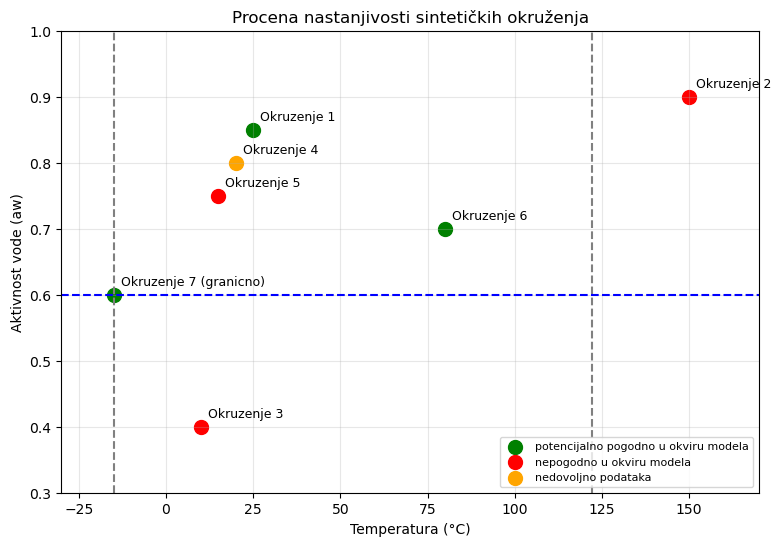

In [6]:
boje = {
    "potencijalno pogodno u okviru modela": "green",
    "nepogodno u okviru modela": "red",
    "nedovoljno podataka": "orange"
}

plt.figure(figsize=(9, 6))

for naziv, red in okruzenja.items():

    klasifikacija = proceni_nastanjivost(red, pragovi)

    plt.scatter(
        red["T_C"],
        red["aw"],
        color=boje[klasifikacija],
        s=100,
        label=klasifikacija
    )

    plt.annotate(
        naziv,
        (red["T_C"], red["aw"]),
        xytext=(5, 7),
        textcoords="offset points",
        fontsize=9
    )

plt.axvline(-15, linestyle="--", color="gray")
plt.axvline(122, linestyle="--", color="gray")
plt.axhline(0.60, linestyle="--", color="blue")

plt.xlabel("Temperatura (°C)")
plt.ylabel("Aktivnost vode (aw)")
plt.title("Procena nastanjivosti sintetičkih okruženja")

plt.xlim(-30, 170)
plt.ylim(0.3, 1.0)
plt.grid(alpha=0.3)

# Uklanjanje ponovljenih stavki iz legende
handles, labels = plt.gca().get_legend_handles_labels()
jedinstveni = dict(zip(labels, handles))
plt.legend(jedinstveni.values(), jedinstveni.keys(),
           loc="lower right", fontsize=8)

plt.show()

In [7]:
# 1. Okruzenje u kome su svi kriterijumi ispunjeni
assert proceni_nastanjivost(
    okruzenja["Okruzenje 1"], pragovi
) == "potencijalno pogodno u okviru modela"


# 2. Okruzenje bez izvora energije
assert proceni_nastanjivost(
    okruzenja["Okruzenje 5"], pragovi
) == "nepogodno u okviru modela"


# 3. Aktivnost vode ispod minimalnog praga
assert proceni_nastanjivost(
    okruzenja["Okruzenje 3"], pragovi
) == "nepogodno u okviru modela"


# 4. Nedostajuci podatak o izvoru energije
assert proceni_nastanjivost(
    okruzenja["Okruzenje 4"], pragovi
) == "nedovoljno podataka"


# 5. Granični scenario: temperatura i aktivnost vode
# tacno na dozvoljenim granicama
assert proceni_nastanjivost(
    okruzenja["Okruzenje 7 (granicno)"], pragovi
) == "potencijalno pogodno u okviru modela"


print("Sve automatske provere su uspesno prosle!")

Sve automatske provere su uspesno prosle!


U početnom modelu minimalna aktivnost vode iznosi 0,60. Sada povećavamo taj prag na 0,80, dok svi ostali kriterijumi ostaju nepromenjeni.

Poređenjem rezultata vidimo da se klasifikacija promenila kod dva okruženja:
- Okruženje 6: Aktivnost vode iznosi 0,70. Pri početnom pragu od 0,60 ispunjava kriterijum, ali pri novom pragu od 0,80 više ga ne ispunjava. Zato prelazi iz kategorije potencijalno pogodnog u nepogodno okruženje.
- Okruženje 7: Aktivnost vode iznosi 0,60, pa takođe više ne zadovoljava novi prag. Iako se temperatura nalazi tačno na donjoj dozvoljenoj granici, okruženje postaje nepogodno zbog nedovoljne aktivnosti vode u odnosu na novi kriterijum.
- Ostala okruženja zadržavaju istu klasifikaciju. Posebno je zanimljivo četvrto okruženje, koje i dalje ima status nedovoljno podataka, jer nedostaje informacija o izvoru energije, dok je aktivnost vode tačno na novom minimumu.

## Zadatak 3 - Naucno tumacenje

### 1. Zašto „potencijalno nastanjivo“ nije isto što i „naseljeno“?

Potencijalna nastanjivost znači da sredina poseduje određene fizičke i hemijske uslove koji bi mogli omogućiti postojanje života. Međutim, to ne znači da je život zaista nastao ili da trenutno postoji u toj sredini. Na primer, prisustvo tečne vode, ugljenika i izvora energije ne predstavlja dokaz postojanja mikroorganizama. Za potvrdu naseljenosti potrebni su direktni dokazi, poput detekcije bioloških molekula ili metaboličke aktivnosti. Zbog toga procena nastanjivosti predstavlja prvi korak u potrazi za životom, a ne konačan zaključak.

### 2. Zašto ne postoji opšteprihvaćena definicija života?

Ne postoji univerzalno prihvaćena definicija života jer svaka predložena definicija ima određene nedostatke i granične slučajeve. Definicija zasnovana isključivo na metabolizmu može obuhvatiti i plamen, koji troši energiju i održava hemijske procese, iako nije živ. Sa druge strane, definicija zasnovana na Darvinovoj evoluciji može isključiti hipotetičke rane oblike života koji su postojali pre razvoja mehanizama nasleđivanja i evolucije kakve danas poznajemo. Takođe, virusi ne mogu samostalno da se razmnožavaju, iako poseduju genetički materijal i učestvuju u evolutivnim procesima. Zbog toga je korisnije kombinovati više osobina života nego oslanjati se na samo jednu.

### 3. Koji kriterijumi nedostaju u našem modelu?

Model obuhvata temperaturu, aktivnost vode, prisustvo tečne vode, izvor energije i ugljenik, ali zanemaruje druge važne faktore. Jedan od njih je pritisak, jer on utiče na mogućnost postojanja tečne vode, posebno pri ekstremnim temperaturama. Takođe, model ne uzima u obzir nivo zračenja, koje može oštetiti biološke molekule, niti biološku dostupnost hranljivih elemenata poput azota, fosfora i sumpora. Važna je i vremenska stabilnost uslova, jer kratkotrajno prisustvo povoljnih uslova ne mora omogućiti nastanak ili održavanje života.

### 4. Kako proveriti robusnost zaključaka?

Robusnost modela može se proveriti ponavljanjem klasifikacije za različite vrednosti pragova, na primer promenom minimalne aktivnosti vode sa 0,60 na 0,80, kao i promenom temperaturnih granica. Zatim se porede rezultati kako bi se utvrdilo da li se zaključci značajno menjaju. Nedostajuće podatke treba tretirati kao Literatura
Laskar, J., Joutel, F., & Robutel, P. (1993). Stabilization of the Earth's obliquity by the Moon. Nature, 361, 615–617.

Originalna ilustracija: Figure 4.8, Life and its Requirements – ASTR3800 Astrobiology.

Izvorni URL: ASTR3800 – Life and its Requirementsnepoznate, a ne automatski kao ispunjene ili neispunjene uslove. Mogu se analizirati različiti mogući scenariji za njihove vrednosti i proveriti kako oni utiču na konačnu klasifikaciju. Ako okruženje zadržava istu kategoriju u većini testiranih slučajeva, zaključak je robusniji.

### Literatura
[Izvorni URL: ASTR3800 – Life and its Requirements](https://saturnaxis.github.io/Astrobio/Chapter_04/Life_Requirements.html)